# Del ciclotrón al sincrotrón: armónicos, anchura y solapamiento
**Dos gráficos interactivos:** radio y rayos X de **1–100 keV**. Ejecutar todas las celdas y usar el panel al final. Notebook autocontenido; no importa archivos locales.

El objetivo es identificar órdenes armónicos individuales, observar cómo se ensanchan y cómo pasan a una envolvente aproximadamente continua. Se calculan armónicos clásicos con funciones de Bessel, no una serie de gaussianas arbitrarias.

Por defecto se comparan **dos escenarios con campos distintos**, uno adecuado para radio y otro para rayos X; comparten la distribución electrónica. La opción **mismo campo** aplica `B_radio_G` a ambos gráficos. En ese caso es perfectamente posible que una de las bandas tenga emisión despreciable: no se desplaza el espectro artificialmente.

In [8]:
# Instalación si hace falta:
# %pip install numpy scipy matplotlib ipywidgets
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
plt.rcParams.update({'figure.figsize':(12,5),'axes.grid':True,'grid.alpha':.2})

## Qué se representa y qué parámetros controlan las líneas
- Campo magnético $B$ en gauss: $\nu_B=eB/(2\pi m_ec)\simeq2.80\,10^6 B[\mathrm G]$ Hz. La energía correspondiente es $E_B\simeq11.58(B/10^{12}\,\mathrm G)$ keV.
- Electrones **isotrópicos en dirección**, con distribución térmica Maxwell–Jüttner (`kT_keV`) o monoenergética (`energia_electron_keV`, energía cinética). La monoenergética separa el ensanchamiento Doppler por pitch del ensanchamiento por dispersión de energías.
- Ángulo $\theta$ entre la línea de visión y el campo: 1–89°. El límite exacto 90° no se usa porque cambia la variable con la que se integra la resonancia.
- Para un electrón con $\mu=\cos\alpha$ (ángulo de pitch), el orden $n$ aparece en
$$\nu_n=\frac{n\nu_B}{\gamma(1-\beta\mu\cos\theta)}.$$
Los picos no están exactamente en $n\nu_B$: hay corrimiento relativista y Doppler. A mayor energía electrónica crecen los órdenes altos y su soporte se solapa. A mayor $n$, una anchura fraccional dada también cubre una fracción mayor de la separación entre órdenes. Aumentar **solo B** desplaza la escala de frecuencias; no cambia la forma adimensional.
- `sigma_ln_B`: dispersión lognormal de B, con B indicado como **mediana**; representa regiones con distintos campos y el mismo número de electrones. `sigma_ln_instrumento`: suavizado gaussiano en $\ln\nu$ de la potencia por intervalo logarítmico. Para anchuras pequeñas equivale aproximadamente a $\sigma_\nu/\nu$. No es un modelo de anchura natural ni colisional.

El eje vertical es $\nu\,dP_\nu/d\Omega=E\,dP_E/d\Omega$, en **erg s⁻¹ sr⁻¹ por electrón**. Se puede normalizar cada panel a su máximo para comparar formas. Para una fuente homogénea ópticamente delgada, multiplicar la potencia direccional por $N_e/d^2$ da el flujo observado por intervalo logarítmico; no hay un factor $4\pi$ adicional.

## Dos regímenes de cálculo explícitos
**Armónicos:** suma hasta `nmax`, con cada orden integrado sobre la distribución electrónica isotrópica. La resonancia se integra analíticamente sobre $\cos\alpha$; la energía térmica se integra por cuadratura. No se oculta la potencia de órdenes omitidos mediante una renormalización.

**Sincrotrón:** aproximación ultrarrelativista continua con $F(x)=x\int_x^\infty K_{5/3}(t)dt$. Para la distribución isotrópica se usa la aproximación de emisión concentrada en la dirección del electrón. Este modo permite explorar energías para las que sumar millones de armónicos resulta impráctico, pero **no resuelve órdenes individuales**. No se añade este continuo a la suma de armónicos: son dos descripciones del mismo proceso.

La implementación parte de [Mahadevan, Narayan & Yi (1996), ecuaciones 2–8](https://arxiv.org/html/astro-ph/9601073). Para el contexto de perfiles individuales, véase [Marcowith & Malzac (2003)](https://www.aanda.org/articles/aa/pdf/2003/37/aa3853.pdf).

In [9]:
"""Emisión clásica ciclotrón/sincrotrón, ópticamente delgada, electrones isotrópicos.
CGS, frecuencia en Hz. Salida por electrón y por estereorradián.
Referencia: Mahadevan, Narayan & Yi 1996, ecuaciones 2–8.
"""
import numpy as np
from scipy.special import jv, jvp, kve, kv
from scipy.integrate import cumulative_trapezoid, trapezoid
from scipy.ndimage import gaussian_filter1d
from numpy.polynomial.legendre import leggauss
from functools import lru_cache

E_CHARGE=4.80320471257e-10
M_E=9.1093837139e-28
C=2.99792458e10
H=6.62607015e-27
KEV=1.602176634e-9
MEC2=510.99895
B_Q=4.414005e13
NU_B_PER_G=E_CHARGE/(2*np.pi*M_E*C)

def gyrofrequency(B):
    return NU_B_PER_G*B

def gamma_pdf(gamma,kT):
    """Maxwell–Jüttner normalizada por unidad de gamma."""
    theta=kT/MEC2
    gamma=np.asarray(gamma)
    p=np.sqrt(np.maximum(0,(gamma-1)*(gamma+1)))
    return gamma*p*np.exp(-(gamma-1)/theta)/(theta*kve(2,1/theta))

def electron_limits(kT,distribution,kinetic_keV):
    if distribution=='termica':
        # Corte de la cola exponencial a T=40 kT.
        return 1+40*kT/MEC2
    if distribution=='monoenergetica': return 1+kinetic_keV/MEC2
    raise ValueError('Distribución: termica o monoenergetica.')

@lru_cache(maxsize=16)
def quadrature(order):
    return leggauss(order)

def harmonic_spectrum(x,order,theta_deg,kT=20.,distribution='termica',
                      kinetic_keV=50.,nquad=80):
    """dP_n/(dnu dOmega) / B; x=nu/nu_B.

    Integra analíticamente la delta de resonancia respecto a mu=cos(pitch).
    La distribución de pitch es isotrópica, dmu/2. Para theta != 90 grados:
    mu=(1-n/(gamma*x))/(beta*cos(theta)).
    El prefactor tras integrar la delta es pi*e²*nu/(c*beta*|cos(theta)|).
    """
    x=np.asarray(x,float)
    angle=np.deg2rad(theta_deg); cs=np.cos(angle); sn=np.sin(angle)
    if not 0<theta_deg<90: raise ValueError('Ángulo matemático: 0 < theta < 90 grados.')
    if np.any(x<=0): raise ValueError('Frecuencias positivas requeridas.')
    if int(order)!=order or order<1: raise ValueError('Orden armónico entero >= 1.')
    a=order/x
    constant=np.pi*E_CHARGE**2*NU_B_PER_G/C
    def angular(g,xx):
        beta=np.sqrt((g-1)*(g+1))/g
        mu=(1-order/(g*xx))/(beta*cs)
        valid=np.abs(mu)<=1
        mu=np.clip(mu,-1,1)
        bpar=beta*mu; bperp=beta*np.sqrt(np.maximum(0,1-mu*mu))
        D=1-bpar*cs
        arg=order*bperp*sn/D
        bracket=((cs-bpar)/sn)**2*jv(order,arg)**2+bperp**2*jvp(order,arg)**2
        return np.where(valid,bracket/beta,0)
    if distribution=='monoenergetica':
        g=1+kinetic_keV/MEC2
        return constant*x/abs(cs)*angular(g,x)
    if distribution!='termica': raise ValueError('Distribución desconocida.')
    # Soporte exacto de la resonancia para gamma: raíces de
    # sin²(theta)*gamma² - 2*a*gamma + a² + cos²(theta) <= 0.
    discriminant=a*a-sn*sn
    root=np.sqrt(np.maximum(0,discriminant))
    # Raíz pequeña racionalizada para evitar cancelaciones.
    lo=(a*a+cs*cs)/(a+abs(cs)*root)
    hi=(a+abs(cs)*root)/(sn*sn)
    upper=1+40*kT/MEC2
    lo=np.maximum(lo,1+1e-12); hi=np.minimum(hi,upper)
    valid=(discriminant>0)&(hi>lo)
    result=np.zeros_like(x)
    if not np.any(valid): return result
    # Integración logarítmica de gamma-1, adecuada también para plasmas fríos.
    z,w=quadrature(nquad)
    low=np.log(lo[valid]-1); high=np.log(hi[valid]-1)
    logt=low[:,None]+(z[None,:]+1)/2*(high-low)[:,None]
    t=np.exp(logt); g=1+t
    integrand=gamma_pdf(g,kT)*angular(g,x[valid,None])*t
    integral=np.sum(integrand*w,axis=1)*(high-low)/2
    result[valid]=constant*x[valid]/abs(cs)*integral
    return result

@lru_cache(maxsize=1)
def synchrotron_table():
    x=np.geomspace(1e-7,700,30000)
    # Integrar desde el extremo alto evita restar integrales casi iguales.
    integral=-cumulative_trapezoid(kv(5/3,x)[::-1],x[::-1],initial=0)[::-1]
    f=x*integral
    return x,f

def synchrotron_F(x):
    x=np.asarray(x,float); table,f=synchrotron_table()
    ans=np.exp(np.interp(np.log(np.maximum(x,1e-300)),np.log(table),
                        np.log(np.maximum(f,1e-300))))
    ans=np.where(x<table[0],2.1495282415344786*np.cbrt(x),ans)
    return np.where(x>650,np.sqrt(np.pi*x/2)*np.exp(-x),ans)

def continuum_spectrum(x,theta_deg,kT=5000.,distribution='termica',
                       kinetic_keV=10000.,nquad=200):
    """dP/(dnu dOmega)/B, aproximación ultrarrelativista de beaming.
    Para electrones isotrópicos: usar pitch=theta y dividir por 4*pi.
    No válido para electrones no relativistas ni como perfil de líneas.
    """
    sn=np.sin(np.deg2rad(theta_deg)); x=np.asarray(x)
    factor=np.sqrt(3)*E_CHARGE**3*sn/(4*np.pi*M_E*C*C)
    if distribution=='monoenergetica':
        g=1+kinetic_keV/MEC2
        return factor*synchrotron_F(x/(1.5*g*g*sn))
    nodes,weights=quadrature(nquad)
    theta=kT/MEC2
    lower=np.log(theta*1e-8); upper=np.log(theta*40)
    t=np.exp(lower+(nodes+1)/2*(upper-lower)); g=1+t
    weight=weights*(upper-lower)/2*t*gamma_pdf(g,kT)
    return factor*(synchrotron_F(x[:,None]/(1.5*g[None,:]**2*sn))@weight)

def broaden_log(y,dlog,sigma_ln_B=0.,sigma_ln_instrument=0.):
    """y=nu*dP/dnu/dOmega. Campo B0*exp(u), u~N(0,sigma_B²).
    El kernel físico incluye B²: <y_B>=exp(2*s²)*G_s[y_0](lognu-2*s²).
    El instrumental es una convolución de potencia en lognu.
    """
    y=np.asarray(y,float); result=y.copy(); index=np.arange(len(y))
    if sigma_ln_B>0:
        smooth=gaussian_filter1d(result,sigma_ln_B/dlog,mode='constant',truncate=6)
        result=np.exp(2*sigma_ln_B**2)*np.interp(
            index-2*sigma_ln_B**2/dlog,index,smooth,left=0,right=0)
    if sigma_ln_instrument>0:
        result=gaussian_filter1d(result,sigma_ln_instrument/dlog,mode='constant',truncate=6)
    return result

def compute_band(B,nu_min,nu_max,theta_deg,kT,distribution,kinetic_keV,
                 mode='armonicos',nmax=100,show_orders=8,sigma_ln_B=0.,
                 sigma_ln_instrument=.015,nquad=80,points=1800):
    """Calcula una banda y los órdenes visibles. Los armónicos no se renormalizan.
    El resultado armónico conserva su truncamiento explícito n<=nmax.
    """
    values=[B,nu_min,nu_max,theta_deg,kT,kinetic_keV,sigma_ln_B,sigma_ln_instrument]
    if not np.all(np.isfinite(values)): raise ValueError('Parámetros no finitos.')
    if min(B,nu_min,kT,kinetic_keV)<=0 or nu_max<=nu_min: raise ValueError('Escalas positivas y banda creciente.')
    if not 1<=theta_deg<=89: raise ValueError('theta debe estar entre 1 y 89 grados.')
    if min(sigma_ln_B,sigma_ln_instrument)<0 or max(sigma_ln_B,sigma_ln_instrument)>.5:
        raise ValueError('Anchuras logarítmicas entre 0 y 0.5.')
    if int(nmax)!=nmax or not 1<=nmax<=2000: raise ValueError('nmax entero entre 1 y 2000.')
    if int(show_orders)!=show_orders or not 0<=show_orders<=min(nmax,20):
        raise ValueError('Mostrar entre 0 y min(nmax,20) órdenes.')
    if not 16<=nquad<=500 or not 300<=points<=10000: raise ValueError('nquad: 16–500; points: 300–10000.')
    if mode not in ['armonicos','sincrotron']: raise ValueError('Modo desconocido.')
    gmax=electron_limits(kT,distribution,kinetic_keV)
    # Margen para convoluciones sin contaminar los extremos de la banda mostrada.
    padding=6*np.hypot(sigma_ln_B,sigma_ln_instrument)+2*sigma_ln_B**2+.05
    dlog=np.log(nu_max/nu_min)/(points-1)
    extra=int(np.ceil(padding/dlog))
    lognu=np.log(nu_min)+np.arange(-extra,points+extra)*dlog
    nu=np.exp(lognu); x=nu/gyrofrequency(B)
    total=np.zeros_like(nu); tail=np.zeros_like(nu); individual={}
    if mode=='armonicos':
        for order in range(1,int(nmax)+1):
            raw=B*nu*harmonic_spectrum(x,order,theta_deg,kT,distribution,kinetic_keV,nquad)
            total+=raw
            if order>max(0,nmax-10): tail+=raw
            if order<=show_orders:
                individual[order]=broaden_log(raw,dlog,sigma_ln_B,sigma_ln_instrument)
    else:
        total=B*nu*continuum_spectrum(x,theta_deg,kT,distribution,kinetic_keV,max(200,nquad))
    total=broaden_log(total,dlog,sigma_ln_B,sigma_ln_instrument)
    tail=broaden_log(tail,dlog,sigma_ln_B,sigma_ln_instrument)
    keep=slice(extra,extra+points)
    total=total[keep]; tail=tail[keep]; nu=nu[keep]
    individual={n:v[keep] for n,v in individual.items()}
    integral=trapezoid(total,np.log(nu))
    fraction=trapezoid(tail,np.log(nu))/integral if integral>0 else 0.
    return dict(nu=nu,total=total,individual=individual,tail_fraction=fraction,
                B=B,nu_B=gyrofrequency(B),gamma_max=gmax,integral=integral)


Task was destroyed but it is pending!
task: <Task pending name='Task-207' coro=<_async_in_context.<locals>.run_in_context() done, defined at /Users/pedro.blay/Library/Python/3.14/lib/python/site-packages/ipykernel/utils.py:57> wait_for=<Task finished name='Task-208' coro=<Kernel.shell_main() done, defined at /Users/pedro.blay/Library/Python/3.14/lib/python/site-packages/ipykernel/kernelbase.py:597> exception=KeyError('96b8415a-9fad-451b-bb0d-c92d90d09bba')> cb=[ZMQStream._run_callback.<locals>._log_error() at /Users/pedro.blay/Library/Python/3.14/lib/python/site-packages/zmq/eventloop/zmqstream.py:563]>
Task exception was never retrieved
future: <Task finished name='Task-208' coro=<Kernel.shell_main() done, defined at /Users/pedro.blay/Library/Python/3.14/lib/python/site-packages/ipykernel/kernelbase.py:597> exception=KeyError('96b8415a-9fad-451b-bb0d-c92d90d09bba')>
Traceback (most recent call last):
  File "/Users/pedro.blay/Library/Python/3.14/lib/python/site-packages/ipykernel/kern

## Parámetros editables
Valores iniciales: armónicos distinguibles. Los preajustes del panel ofrecen ejemplos fríos, de solapamiento y de continuo sincrotrón.

In [10]:
parametros = dict(
    B_radio_G=100.0,              # campo del escenario radio [G]
    B_X_G=1e11,                  # campo del escenario X [G]
    mismo_campo=False,
    radio_min_GHz=0.01,
    radio_max_GHz=30.0,
    kT_keV=20.0,
    distribucion='termica',      # 'termica' o 'monoenergetica'
    energia_electron_keV=50.0,   # solo distribución monoenergética
    theta_grados=75.0,           # ángulo observador–B
    modo='armonicos',            # 'armonicos' o 'sincrotron'
    nmax=100,                    # aumentar y comprobar convergencia
    mostrar_ordenes=8,           # primeros órdenes coloreados, 0–20
    sigma_ln_B=0.0,
    sigma_ln_instrumento=0.015,  # resolución explícita; usar 0 para quitarla
    normalizar=False,
    nquad=80,                    # nodos de cuadratura de energía
    puntos=1800,
)


Radio: νB = 2.7992e+08 Hz; EB = 1.1577e-09 keV; potencia en banda = 9.6348e-14 erg/s/sr/electrón
  Últimos min(10,nmax) órdenes: 0.00% de la potencia calculada en banda.
Rayos X: νB = 2.7992e+17 Hz; EB = 1.1577 keV; potencia en banda = 87146 erg/s/sr/electrón
  Últimos min(10,nmax) órdenes: 0.00% de la potencia calculada en banda.
Nota: La prueba de convergencia es duplicar nmax, nquad y puntos. Una cola pequeña por sí sola no certifica convergencia en toda la banda.


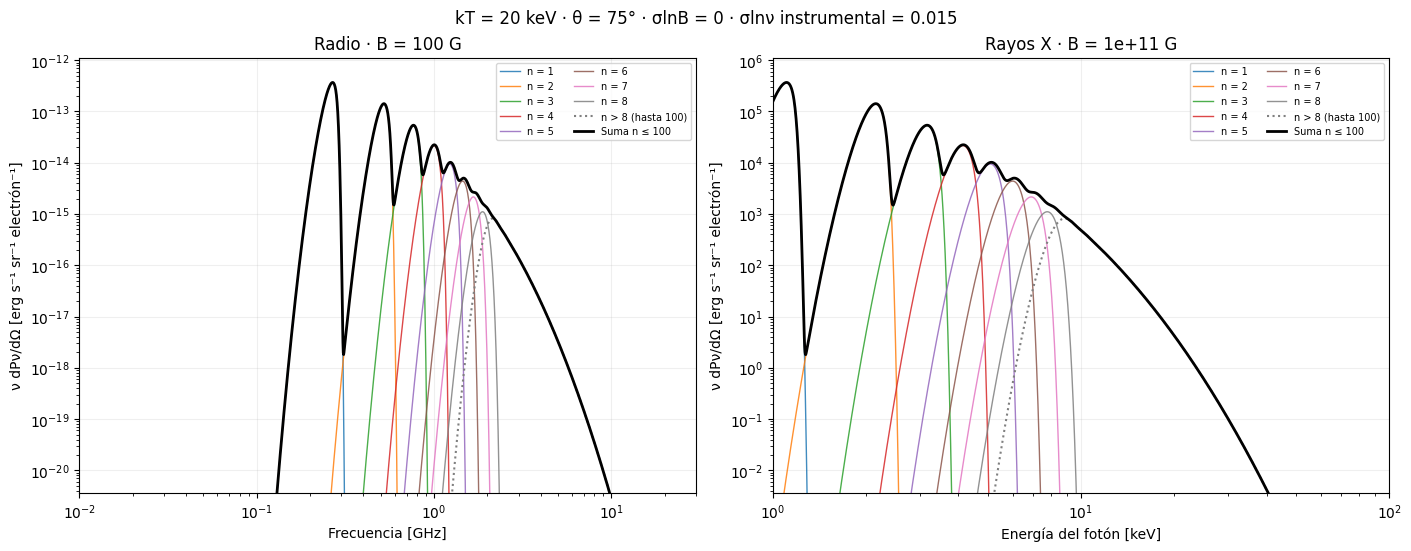

In [11]:
def dibujar_espectros(**p):
    if p['radio_min_GHz']<=0 or p['radio_max_GHz']<=p['radio_min_GHz']:
        raise ValueError('Banda radio positiva y creciente.')
    fields=[p['B_radio_G'],p['B_radio_G'] if p['mismo_campo'] else p['B_X_G']]
    bands=[(p['radio_min_GHz']*1e9,p['radio_max_GHz']*1e9),(KEV/H,100*KEV/H)]
    options=dict(theta_deg=p['theta_grados'],kT=p['kT_keV'],distribution=p['distribucion'],
        kinetic_keV=p['energia_electron_keV'],mode=p['modo'],nmax=p['nmax'],
        show_orders=p['mostrar_ordenes'],sigma_ln_B=p['sigma_ln_B'],
        sigma_ln_instrument=p['sigma_ln_instrumento'],nquad=p['nquad'],points=p['puntos'])
    result=[compute_band(B,*band,**options) for B,band in zip(fields,bands)]
    fig,axes=plt.subplots(1,2,figsize=(14,5.4),constrained_layout=True)
    names=['Radio','Rayos X']; messages=[]
    for i,(ax,r) in enumerate(zip(axes,result)):
        x=r['nu']/1e9 if i==0 else H*r['nu']/KEV
        peak=np.max(r['total']); scale=peak if p['normalizar'] and peak>0 else 1.
        def plot_curve(y,label,**style):
            ax.plot(x,np.where(y>max(peak*1e-12,1e-300),y/scale,np.nan),label=label,**style)
        for order,y in r['individual'].items():
            plot_curve(y,f'n = {order}',lw=1,alpha=.85)
        if r['individual']:
            remainder=np.maximum(0,r['total']-sum(r['individual'].values()))
            plot_curve(remainder,f'n > {p["mostrar_ordenes"]} (hasta {p["nmax"]})',
                       color='gray',ls=':',lw=1.5)
        label=f'Suma n ≤ {p["nmax"]}' if p['modo']=='armonicos' else 'Continuo sincrotrón'
        plot_curve(r['total'],label,color='black',lw=2)
        ax.set_xscale('log'); ax.set_yscale('log')
        ax.set_xlim(bands[i][0]/(1e9 if i==0 else KEV/H),bands[i][1]/(1e9 if i==0 else KEV/H))
        if peak>1e-290:
            ax.set_ylim(peak/scale*1e-8,peak/scale*3)
        else:
            ax.set_ylim(1e-30,1)
            ax.text(.5,.5,'Sin señal calculable en esta banda',ha='center',transform=ax.transAxes)
        ax.set_xlabel('Frecuencia [GHz]' if i==0 else 'Energía del fotón [keV]')
        ax.set_ylabel('Potencia / máximo del panel' if p['normalizar'] else
                      'ν dPν/dΩ [erg s⁻¹ sr⁻¹ electrón⁻¹]')
        ax.set_title(f'{names[i]} · B = {r["B"]:.3g} G')
        ax.legend(fontsize=7,ncol=2,loc='best')
        eb=H*r['nu_B']/KEV
        print(f'{names[i]}: νB = {r["nu_B"]:.5g} Hz; EB = {eb:.5g} keV; '
              f'potencia en banda = {r["integral"]:.5g} erg/s/sr/electrón')
        if p['modo']=='armonicos':
            print(f'  Últimos min(10,nmax) órdenes: {r["tail_fraction"]:.2%} de la potencia calculada en banda.')
            if r['tail_fraction']>.01:
                messages.append(f'{names[i]}: cola armónica relevante; aumentar nmax y comparar.')
            if peak==0:
                messages.append(f'{names[i]}: cero puede indicar una banda fuera de los órdenes calculados; '
                                'no demuestra ausencia física de emisión.')
        # Parámetros de validez cuántica, conservadores sobre la cola electrónica.
        chi=r['gamma_max']*r['B']/B_Q
        energy_scale=p['kT_keV'] if p['distribucion']=='termica' else p['energia_electron_keV']
        if eb/energy_scale>.1:
            messages.append(f'{names[i]}: EB/escala electrónica = {eb/energy_scale:.2g}; '
                            'la cuantización de Landau puede importar. Espectro clásico ilustrativo.')
        if chi>.05:
            messages.append(f'{names[i]}: gamma_max·B/BQ = {chi:.2g}; comprobar correcciones cuánticas, '
                            'especialmente en la cola electrónica.')
    if p['modo']=='sincrotron':
        theta=p['kT_keV']/MEC2
        if (p['distribucion']=='termica' and theta<3) or (
            p['distribucion']=='monoenergetica' and 1+p['energia_electron_keV']/MEC2<10):
            messages.append('Continuo fuera de su régimen ultrarrelativista: usar modo armónicos.')
    if p['modo']=='armonicos':
        messages.append('La prueba de convergencia es duplicar nmax, nquad y puntos. '
                        'Una cola pequeña por sí sola no certifica convergencia en toda la banda.')
    for message in dict.fromkeys(messages): print('Nota:',message)
    title=(f'kT = {p["kT_keV"]:g} keV' if p['distribucion']=='termica' else
           f'Te = {p["energia_electron_keV"]:g} keV')
    fig.suptitle(f'{title} · θ = {p["theta_grados"]:g}° · '
                 f'σlnB = {p["sigma_ln_B"]:g} · σlnν instrumental = {p["sigma_ln_instrumento"]:g}')
    plt.show()
    return dict(radio=result[0],rayos_X=result[1],fig=fig,parametros=p.copy())

resultado = dibujar_espectros(**parametros)


## Panel interactivo
Seleccionar un preajuste modifica los controles; pulsar **Calcular** para obtener los dos gráficos. El modo armónico puede tardar más al aumentar `nmax` o la temperatura.

1. **Armónicos separados**: identificar los órdenes y después aumentar kT.
2. **Solapamiento térmico**: comparar 20 y 100 keV con el mismo B y ángulo.
3. **Campo inhomogéneo**: añadir anchura de B manteniendo la distribución electrónica.
4. **Sincrotrón relativista**: continuo a kT = 5 MeV; el escenario X usa B menor para reducir efectos cuánticos.
5. **Mismo campo, dos bandas**: demuestra la separación de escalas; un campo adecuado para radio con estos electrones no produce necesariamente rayos X apreciables.

Los presets son ejemplos independientes, no una evolución temporal del mismo plasma. El cambio de campo en el cuarto se indica explícitamente.

In [12]:
try:
    import ipywidgets as W
    from IPython.display import display,clear_output
    style={'description_width':'160px'}
    def number(value,description): return W.FloatText(value=value,description=description,style=style)
    controles={
        'B_radio_G':number(parametros['B_radio_G'],'B radio [G]'),
        'B_X_G':number(parametros['B_X_G'],'B rayos X [G]'),
        'mismo_campo':W.Checkbox(value=False,description='Mismo campo en ambas bandas',indent=False),
        'radio_min_GHz':number(parametros['radio_min_GHz'],'Radio mínimo [GHz]'),
        'radio_max_GHz':number(parametros['radio_max_GHz'],'Radio máximo [GHz]'),
        'kT_keV':number(parametros['kT_keV'],'kT [keV]'),
        'energia_electron_keV':number(parametros['energia_electron_keV'],'E cinética mono [keV]'),
        'distribucion':W.Dropdown(options=[('Maxwell–Jüttner','termica'),('Monoenergética','monoenergetica')],
                                 value=parametros['distribucion'],description='Electrones',style=style),
        'theta_grados':W.FloatSlider(value=75,min=1,max=89,step=1,description='Ángulo θ [°]',style=style),
        'modo':W.Dropdown(options=[('Armónicos exactos clásicos','armonicos'),('Continuo sincrotrón','sincrotron')],
                         value='armonicos',description='Modelo',style=style),
        'nmax':W.IntText(value=100,description='Orden máximo',style=style),
        'mostrar_ordenes':W.IntSlider(value=8,min=0,max=20,description='Órdenes coloreados',style=style),
        'sigma_ln_B':W.FloatSlider(value=0,min=0,max=.5,step=.005,readout_format='.3f',description='σ ln B',style=style),
        'sigma_ln_instrumento':W.FloatSlider(value=.015,min=0,max=.2,step=.001,readout_format='.3f',
                                            description='σ ln ν instrumental',style=style),
        'normalizar':W.Checkbox(value=False,description='Normalizar cada panel',indent=False),
    }
    presets={
        'Armónicos separados':dict(kT_keV=20,theta_grados=75,nmax=100,sigma_ln_B=0,
                                   modo='armonicos',B_X_G=1e11,mismo_campo=False),
        'Solapamiento térmico':dict(kT_keV=100,theta_grados=60,nmax=300,sigma_ln_B=0,
                                    modo='armonicos',B_X_G=1e11,mismo_campo=False),
        'Campo inhomogéneo':dict(kT_keV=20,theta_grados=75,nmax=100,sigma_ln_B=.15,
                                  modo='armonicos',B_X_G=1e11,mismo_campo=False),
        'Sincrotrón relativista':dict(kT_keV=5000,theta_grados=60,sigma_ln_B=0,
                                     modo='sincrotron',B_X_G=1e9,mismo_campo=False),
        'Mismo campo, dos bandas':dict(kT_keV=20,theta_grados=75,nmax=100,sigma_ln_B=0,
                                       modo='armonicos',mismo_campo=True),
    }
    selector=W.Dropdown(options=list(presets),description='Preajuste',style=style)
    def aplicar(change):
        for key,value in presets[change['new']].items(): controles[key].value=value
        controles['distribucion'].value='termica'
        controles['B_radio_G'].value=100
    selector.observe(aplicar,names='value')
    boton=W.Button(description='Calcular',button_style='primary')
    output=W.Output()
    def actualizar(_):
        global resultado
        boton.disabled=True
        with output:
            clear_output(wait=True)
            try:
                resultado=dibujar_espectros(**(parametros | {key:w.value for key,w in controles.items()}))
            except (ValueError,ArithmeticError) as exc: print(str(exc))
            finally: boton.disabled=False
    boton.on_click(actualizar)
    display(W.VBox([selector,W.HBox([W.VBox(list(controles.values())[:8]),
                                    W.VBox(list(controles.values())[8:])]),boton,output]))
except ImportError:
    print('Instale ipywidgets para usar el panel; las celdas de parámetros funcionan sin él.')

## Exportar
Ejecutar esta celda después del cálculo deseado. Se exportan valores físicos aunque la vista esté normalizada, junto con los parámetros de la ejecución.

In [13]:
import json
carpeta=Path('resultados_ciclosincrotron'); carpeta.mkdir(exist_ok=True)
for nombre in ['radio','rayos_X']:
    r=resultado[nombre]
    orders=list(r['individual'])
    table=np.column_stack([r['nu'],H*r['nu']/KEV,r['total']]+[r['individual'][n] for n in orders])
    header='nu_Hz,E_keV,nu_dPnu_dOmega_erg_s_sr_electron'+''.join(f',armonico_{n}' for n in orders)
    np.savetxt(carpeta/f'{nombre}.csv',table,delimiter=',',header=header,comments='')
(carpeta/'parametros.json').write_text(json.dumps(resultado['parametros'],indent=2),encoding='utf-8')
resultado['fig'].savefig(carpeta/'espectros.png',dpi=170)
print('Exportado en:',carpeta.resolve())

Exportado en: /Users/pedro.blay/Downloads/bexrb/notebooks/resultados_ciclosincrotron


## Límites y comprobaciones recomendadas
El cálculo describe **emisión clásica, incoherente, ópticamente delgada**, en un campo local uniforme o una mezcla lognormal de campos. No incluye autoabsorción, efecto Razin, frecuencia de corte del plasma, maser, enfriamiento de la distribución, propagación polarizada ni transferencia radiativa. En radio, estos procesos pueden cambiar mucho el espectro observado.

En campos altos, comprobar $B/B_Q$, $\chi\sim\gamma B/B_Q$ y $E_B/kT$, con $B_Q=4.414\times10^{13}$ G. Si la separación de niveles de Landau o el recoil cuántico importan, los armónicos clásicos no predicen correctamente las líneas. El panel muestra avisos; no implementa ciclotrón cuántico. Tampoco modela líneas de absorción ciclotrón de estrellas de neutrones.

La suma hasta `nmax` es finita. Para kT grandes, el modo armónico puede subestimar la cola; aumentar `nmax` hasta estabilizar el resultado o usar el continuo **solo en régimen ultrarrelativista**. La contribución de los últimos diez órdenes es un indicador, no una cota del error. El corte de la distribución térmica está en energía cinética $40kT$.

Para estudiar ensanchamiento físico, repetir con `sigma_ln_instrumento=0` y aumentar `puntos` y `nquad`. Las líneas más estrechas que la malla no quedan resueltas. Las curvas se dibujan hasta ocho décadas por debajo del máximo del panel para mantenerlas legibles; los CSV conservan todos los valores calculados.

**Convergencia:** duplicar `nmax`, `nquad` y `puntos` por separado. En la distribución monoenergética los bordes del perfil pueden ser muy agudos. El archivo de pruebas adjunto verifica normalización de electrones, potencia total en el límite no relativista, escalado con B, conservación del suavizado instrumental y convergencia de los primeros armónicos.